# Atención y transformer

softmax(QKᵀ/√d)·V en NumPy, la máscara causal y varias cabezas, verificadas contra PyTorch.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)

In [2]:
import torch
from research_paths.attention import causal_mask, multi_head_attention, scaled_dot_product_attention

q, k, v = (rng.normal(size=(6, 8)) for _ in range(3))
out, w = scaled_dot_product_attention(q, k, v, causal_mask(6))
ref = torch.nn.functional.scaled_dot_product_attention(
    *(torch.tensor(t) for t in (q, k, v)), is_causal=True
)
print("diferencia máxima con torch:", np.abs(out - ref.numpy()).max())

diferencia máxima con torch: 2.220446049250313e-16


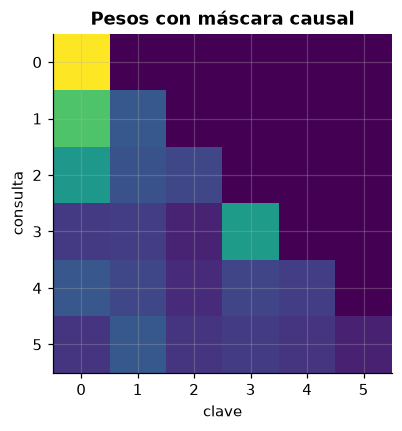

In [3]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(w, cmap="viridis")
ax.set(title="Pesos con máscara causal", xlabel="clave", ylabel="consulta");

## ¿Por qué dividir por √d?

Sin escalar, el producto punto crece con la dimensión y el softmax se satura: casi todo el peso va a una sola clave y el gradiente se apaga.

In [4]:
for d in (4, 64, 1024):
    qd, kd = rng.normal(size=(2, 50, d))
    _, w_raw = scaled_dot_product_attention(qd * np.sqrt(d), kd, np.eye(50))  # deshace el /√d
    _, w_ok = scaled_dot_product_attention(qd, kd, np.eye(50))
    raw, ok = w_raw.max(-1).mean(), w_ok.max(-1).mean()
    print(f"d={d:5d}: peso máximo medio sin escalar {raw:.2f} · escalado {ok:.2f}")

d=    4: peso máximo medio sin escalar 0.37 · escalado 0.15
d=   64: peso máximo medio sin escalar 0.78 · escalado 0.12
d= 1024: peso máximo medio sin escalar 0.95 · escalado 0.13


## Varias cabezas

Cada cabeza mira el mismo texto con proyecciones distintas.

In [5]:
x = rng.normal(size=(5, 8))
W = [rng.normal(size=(8, 8)) for _ in range(4)]
out, weights = multi_head_attention(x, *W, num_heads=2)
weights.shape  # (cabezas, n, n)

(2, 5, 5)